# Clustering

In [Unsupervised Learning](../theme-1/05_unsupervised_learning.ipynb) you fitted HDBSCAN to the latitude and longitude of houses in California, and the clusters matched cities such as Los Angeles and San Diego. On the [What is Machine Learning?](../theme-1/01_what_is_machine_learning.qmd) page (section 8), clustering was the example of unsupervised learning: the data has features but no labels, and the model looks for groups of similar points.

In this notebook you will see how clustering algorithms work. You start with scikit-learn's `KMeans` on a small dataset and look at what it returns. Then you look inside: you measure how similar two points are, build the K-Means algorithm yourself and check that it gives the same result as scikit-learn. After that you use two measures to choose the number of clusters: the elbow method and the silhouette score. Then you will see where K-Means fails, and how density-based methods such as HDBSCAN handle those cases.

### Outline

1. `KMeans` in scikit-learn
2. What makes two points similar
3. Why scaling matters
4. K-Means by hand
5. Choosing k: inertia and the elbow
6. The silhouette score
7. Where K-Means fails
8. Density-based clustering
9. Exercise

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. `KMeans` in scikit-learn

A clustering algorithm puts similar points in the same group. We start with six points and two features. As in every clustering problem, there are no labels: the points have features, but nobody has told us which group each point belongs to.

In [2]:
# DUMMY DATA
# DO NOT MODIFY
points = np.array([
    [1.0, 1.0],
    [1.5, 2.0],
    [2.0, 1.5],
    [6.0, 5.0],
    [7.0, 5.5],
    [6.5, 6.5],
])
names = ['A', 'B', 'C', 'D', 'E', 'F']

Text(0, 0.5, 'feature_2')

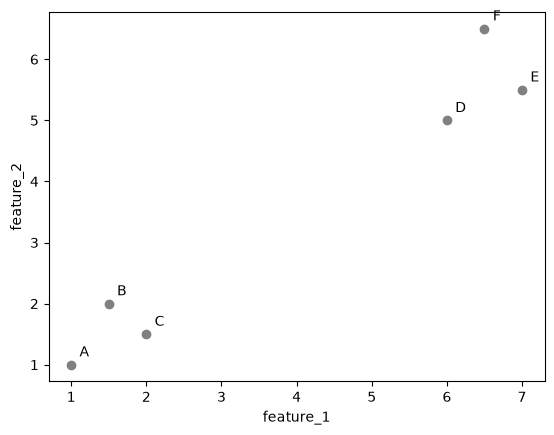

In [3]:
plt.figure(dpi=100)
plt.scatter(points[:, 0], points[:, 1], color='grey')
for name, (x1, x2) in zip(names, points):
    plt.annotate(name, (x1, x2), textcoords='offset points', xytext=(6, 6))
plt.xlabel('feature_1')
plt.ylabel('feature_2')

You can see two groups: A, B and C at the bottom left, and D, E and F at the top right. Let's see if an algorithm finds the same groups.

**K-Means** is the most widely used clustering algorithm. You tell it how many clusters to look for, and it splits the points into that many groups. The K in its name is that number. In scikit-learn the number is set with `n_clusters`. Note that `fit` only gets the features, because there are no labels to learn from.

In [4]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=2, random_state=0)
kmeans.fit(points)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",2
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",0
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](2, 2)","[[

After fitting, `labels_` holds the cluster of each point:

In [5]:
pd.DataFrame({'point': names, 'cluster': kmeans.labels_})

,point,cluster
0,A,1
1,B,1
2,C,1
3,D,0
4,E,0
5,F,0


K-Means has put A, B and C in one cluster and D, E and F in the other, the same groups that you saw in the plot. The cluster numbers are only names. Cluster 1 is not better or larger than cluster 0, and with another `random_state` the two numbers can swap.

K-Means also describes each cluster by its center, the **centroid**. It is stored in `cluster_centers_`, one row per cluster. The plot colors each point by its cluster and marks the centroids with black crosses.

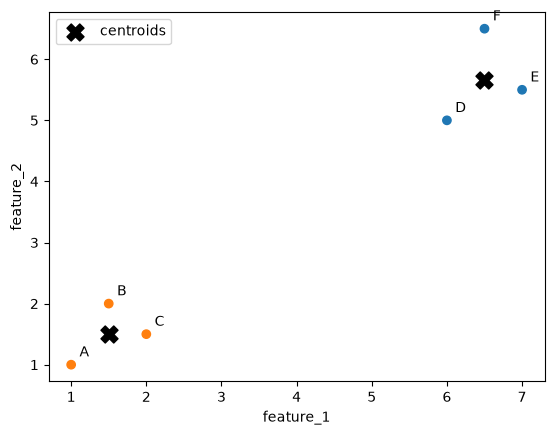

In [6]:
cluster_colors = np.array(['tab:blue', 'tab:orange'])

plt.figure(dpi=100)
plt.scatter(points[:, 0], points[:, 1], color=cluster_colors[kmeans.labels_])
for name, (x1, x2) in zip(names, points):
    plt.annotate(name, (x1, x2), textcoords='offset points', xytext=(6, 6))
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], color='black', marker='X', s=150, label='centroids')
plt.xlabel('feature_1')
plt.ylabel('feature_2')
plt.legend()

Each centroid lies in the middle of its cluster. A fitted `KMeans` can also place new points: `predict` puts a new point in the cluster with the nearest centroid. A point at (2, 2) goes to the cluster of A, B and C, and a point at (6, 6) to the cluster of D, E and F:

In [7]:
kmeans.predict([[2, 2], [6, 6]])

array([1, 0], dtype=int32)

K-Means found the groups from the features alone. To do that, it has to decide which points are close to each other and where to put the centroids. The rest of this notebook looks at how it does that: section 2 measures how similar two points are, and section 4 builds the K-Means algorithm step by step.

## 2. What makes two points similar

To decide which points belong together, a clustering algorithm needs a number that says how similar two points are. Most clustering algorithms use the distance between the points: a small distance means the points are similar, a large distance means they are different.

An algorithm cannot look at a plot, so it has to calculate which points are close.

The most common distance is the **Euclidean distance**, the length of a straight line between two points. With two features, it comes from the theorem of Pythagoras. Take points A and D. The difference in `feature_1` is one side of a right-angled triangle, the difference in `feature_2` is the other side, and the distance is the long side:

$$d(A, D) = \sqrt{(A_1 - D_1)^2 + (A_2 - D_2)^2}$$

The plot below draws this triangle.

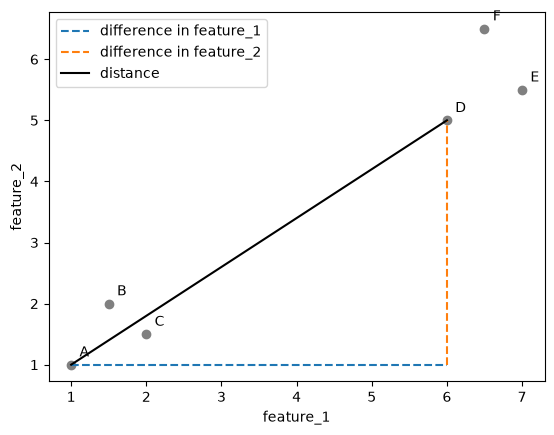

In [8]:
A, D = points[0], points[3]

plt.figure(dpi=100)
plt.scatter(points[:, 0], points[:, 1], color='grey')
for name, (x1, x2) in zip(names, points):
    plt.annotate(name, (x1, x2), textcoords='offset points', xytext=(6, 6))
plt.plot([A[0], D[0]], [A[1], A[1]], color='tab:blue', ls='--', label='difference in feature_1')
plt.plot([D[0], D[0]], [A[1], D[1]], color='tab:orange', ls='--', label='difference in feature_2')
plt.plot([A[0], D[0]], [A[1], D[1]], color='black', label='distance')
plt.xlabel('feature_1')
plt.ylabel('feature_2')
plt.legend()

In code, we square the differences for all features, add them up and take the square root. Written this way, the function works for any number of features, not just two.

In [9]:
def distance(a, b):
    return np.sqrt(np.sum((a - b) ** 2))

In [10]:
print(f"d(A, D) = {distance(points[0], points[3]):.2f}")
print(f"d(A, B) = {distance(points[0], points[1]):.2f}")

d(A, D) = 6.40
d(A, B) = 1.12


A is much closer to B than to D. Let's draw the distance from A to every other point.

Text(0, 0.5, 'feature_2')

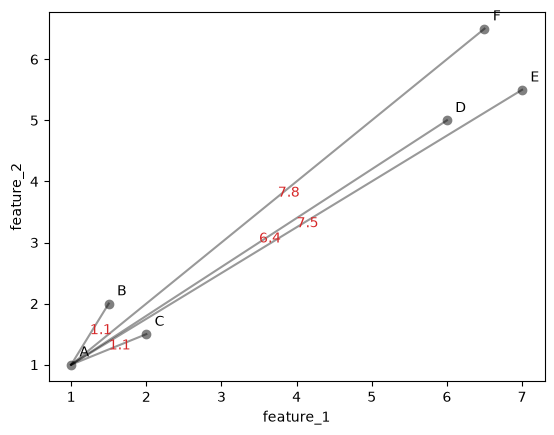

In [11]:
plt.figure(dpi=100)
plt.scatter(points[:, 0], points[:, 1], color='grey')
for name, (x1, x2) in zip(names, points):
    plt.annotate(name, (x1, x2), textcoords='offset points', xytext=(6, 6))
for p in points[1:]:
    plt.plot([A[0], p[0]], [A[1], p[1]], color='black', alpha=0.4)
    middle = (A + p) / 2
    plt.annotate(f"{distance(A, p):.1f}", middle, color='tab:red')
plt.xlabel('feature_1')
plt.ylabel('feature_2')

A clustering algorithm needs the distance between every pair of points. We collect them in a table, the distance matrix: the value in row `i` and column `j` is the distance between point `i` and point `j`.

In [12]:
n_points = len(points)
distances = np.zeros((n_points, n_points))
for i in range(n_points):
    for j in range(n_points):
        distances[i, j] = distance(points[i], points[j])

pd.DataFrame(distances, index=names, columns=names).round(2)

,A,B,C,D,E,F
A,0.00,1.12,1.12,6.40,7.50,7.78
B,1.12,0.00,0.71,5.41,6.52,6.73
C,1.12,0.71,0.00,5.32,6.40,6.73
D,6.40,5.41,5.32,0.00,1.12,1.58
E,7.50,6.52,6.40,1.12,0.00,1.12
F,7.78,6.73,6.73,1.58,1.12,0.00


scikit-learn has a function that computes the same matrix. Let's check that our numbers match.

In [13]:
from sklearn.metrics import pairwise_distances
np.allclose(distances, pairwise_distances(points))

True

A heatmap shows the matrix as colors: dark is a small distance, light is a large one.

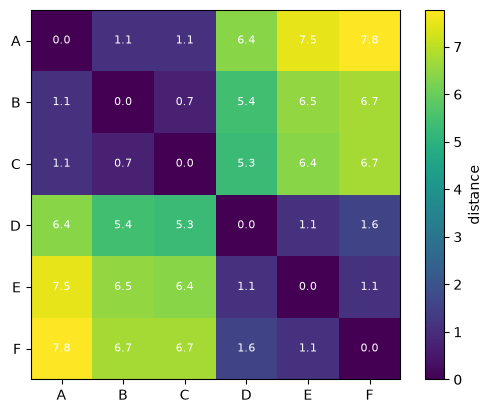

In [14]:
plt.figure(dpi=100)
plt.imshow(distances, cmap='viridis')
plt.colorbar(label='distance')
plt.xticks(range(n_points), names)
plt.yticks(range(n_points), names)
for i in range(n_points):
    for j in range(n_points):
        plt.text(j, i, f"{distances[i, j]:.1f}", ha='center', va='center', color='white', fontsize=8)

The two groups show up as two dark blocks: small distances among A, B and C, and small distances among D, E and F. The distances between the groups are large.

Take a moment to reflect: why is the diagonal of the matrix zero, and why is the matrix the same on both sides of the diagonal?

## 3. Why scaling matters

The distance adds up the differences of all features. If one feature has much larger numbers than the others, its differences dominate the sum, and the other features hardly count.

Here is a made-up dataset of houses with two features: the number of rooms (1 to 6) and the floor area in square meters (40 to 200).

In [15]:
# DUMMY DATA GENERATION
# DO NOT MODIFY
np.random.seed(0)
n = 50
rooms = np.random.randint(1, 7, size=n)
area = np.random.uniform(40, 200, size=n).round()
houses = np.column_stack([rooms, area]).astype(float)

# three houses we will compare
house_R = np.array([3, 100])  # 3 rooms, 100 m²
house_S = np.array([6, 102])  # 6 rooms, 102 m²
house_T = np.array([3, 115])  # 3 rooms, 115 m²
houses = np.vstack([houses, house_R, house_S, house_T])
houses.shape

(53, 2)

House S has the same floor area as house R but twice as many rooms. House T has the same number of rooms as R and 15 m² more floor area. Most people would call T the house that is more similar to R. Let's see what the distance says.

In [16]:
print(f"d(R, S) = {distance(house_R, house_S):.1f}")
print(f"d(R, T) = {distance(house_R, house_T):.1f}")

d(R, S) = 3.6
d(R, T) = 15.0


By the distance, S is much closer to R. A difference of 3 rooms adds 3² = 9 to the sum, while a difference of 15 m² adds 15² = 225. The floor area decides almost everything because its numbers are larger, not because it is more important.

The plot shows the problem when both axes use the same scale: all houses lie on what looks like a thin band, because the number of rooms hardly varies compared with the floor area.

Text(0, 0.5, 'area (m²)')

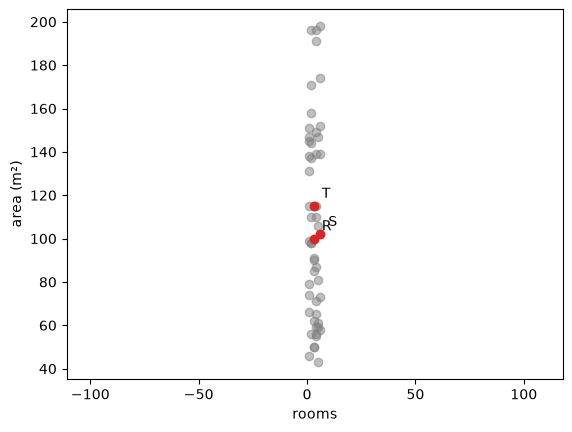

In [17]:
plt.figure(dpi=100)
plt.scatter(houses[:, 0], houses[:, 1], color='grey', alpha=0.5)
for name, h in zip(['R', 'S', 'T'], [house_R, house_S, house_T]):
    plt.scatter(*h, color='tab:red')
    plt.annotate(name, h, textcoords='offset points', xytext=(6, 6))
plt.axis('equal')  # the same scale on both axes, as the distance sees it
plt.xlabel('rooms')
plt.ylabel('area (m²)')

The solution is scaling, which you used in [Data Preparation](../theme-2/01_data_prep.ipynb). `StandardScaler` subtracts the mean of each feature and divides by its standard deviation, so every feature ends up with mean 0 and standard deviation 1. After scaling, a difference of one unit means the same for both features: one standard deviation.

In [18]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
houses_scaled = scaler.fit_transform(houses)

# the same calculation by hand
houses_by_hand = (houses - houses.mean(axis=0)) / houses.std(axis=0)
np.allclose(houses_scaled, houses_by_hand)

True

In [19]:
R_scaled, S_scaled, T_scaled = houses_scaled[-3], houses_scaled[-2], houses_scaled[-1]
print(f"d(R, S) after scaling = {distance(R_scaled, S_scaled):.2f}")
print(f"d(R, T) after scaling = {distance(R_scaled, T_scaled):.2f}")

d(R, S) after scaling = 1.79
d(R, T) after scaling = 0.34


Text(0, 0.5, 'area (scaled)')

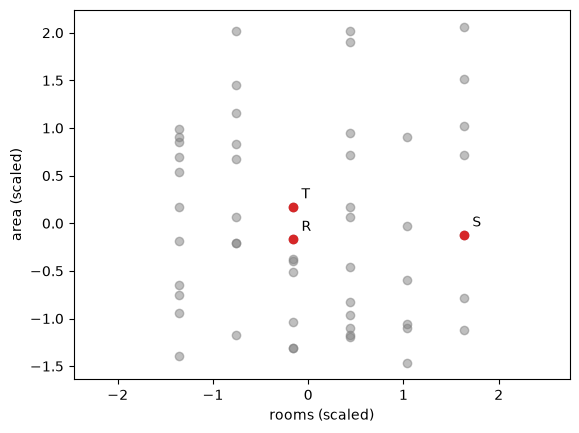

In [20]:
plt.figure(dpi=100)
plt.scatter(houses_scaled[:, 0], houses_scaled[:, 1], color='grey', alpha=0.5)
for name, h in zip(['R', 'S', 'T'], [R_scaled, S_scaled, T_scaled]):
    plt.scatter(*h, color='tab:red')
    plt.annotate(name, h, textcoords='offset points', xytext=(6, 6))
plt.axis('equal')
plt.xlabel('rooms (scaled)')
plt.ylabel('area (scaled)')

After scaling, T is the nearest house to R, and both features count. Clustering algorithms use distances, so they have the same problem: without scaling, the features with the largest numbers decide the clusters. Scale your features before you cluster them, unless they are already in the same unit, as latitude and longitude are.

## 4. K-Means by hand

We create a dataset with three groups of points. We made the groups ourselves, so we know they are there, but the algorithm only gets the features.

In [21]:
# DUMMY DATA GENERATION
# DO NOT MODIFY
np.random.seed(0)
n = 50  # number of points per group
group_centers = np.array([[2, 2], [7, 3], [4, 7]])
X = np.concatenate([np.random.normal(center, 0.8, size=(n, 2)) for center in group_centers])
X.shape

(150, 2)

Text(0, 0.5, 'feature_2')

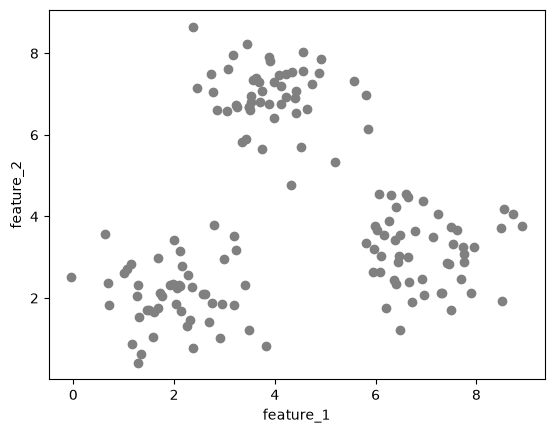

In [22]:
plt.figure(dpi=100)
plt.scatter(X[:, 0], X[:, 1], color='grey')
plt.xlabel('feature_1')
plt.ylabel('feature_2')

In section 1 you saw that K-Means describes each cluster by its centroid. The centroid is the mean of the points in the cluster. You choose the number of clusters K yourself. The algorithm then works as follows:

1. Pick K points from the data at random. These are the starting centroids.
2. Assign step: give every point to its nearest centroid.
3. Update step: move every centroid to the mean of the points assigned to it.
4. Repeat steps 2 and 3 until the centroids stop moving.

We go through these steps one at a time with K = 3.

In [23]:
k = 3
np.random.seed(5)
start = np.random.choice(len(X), size=k, replace=False)  # k random row numbers
centroids = X[start]
centroids

array([[6.01965158, 3.67549038],
       [3.75129106, 7.07792013],
       [3.52214714, 6.80966262]])

We will plot clusters many times in this notebook, so we write a small function for it. Points are colored by their cluster; centroids are black crosses.

In [24]:
colors = np.array(plt.cm.tab10.colors)

def plot_clusters(X, labels=None, centroids=None, ax=None, title=None):
    if ax is None:
        plt.figure(dpi=100)
        ax = plt.gca()
    if labels is None:
        ax.scatter(X[:, 0], X[:, 1], color='grey', alpha=0.6)
    else:
        ax.scatter(X[:, 0], X[:, 1], color=colors[labels % 10], alpha=0.6)
    if centroids is not None:
        ax.scatter(centroids[:, 0], centroids[:, 1], color='black', marker='X', s=150)
    ax.set_xlabel('feature_1')
    ax.set_ylabel('feature_2')
    if title is not None:
        ax.set_title(title)

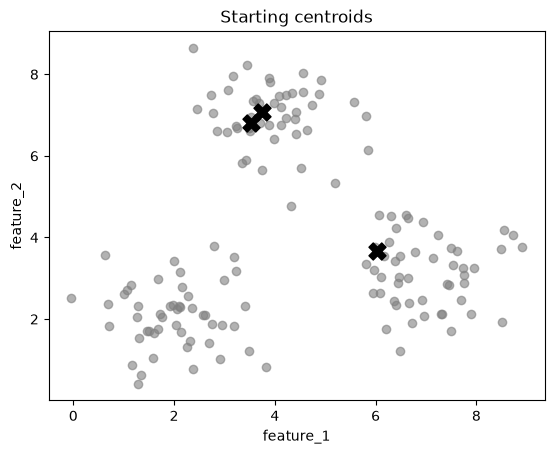

In [25]:
plot_clusters(X, centroids=centroids, title='Starting centroids')

Two of the three starting centroids are in the top group, and none is in the bottom left group. This is a poor start; the steps below show how K-Means recovers from it.

Assign step: for every point, we compute the distance to each centroid and take the number of the nearest one. `np.argmin` returns the position of the smallest value in a list.

In [26]:
def assign(X, centroids):
    labels = []
    for x in X:
        distances_to_centroids = [distance(x, c) for c in centroids]
        labels.append(np.argmin(distances_to_centroids))
    return np.array(labels)

labels = assign(X, centroids)
labels[:10]

array([0, 2, 0, 0, 0, 2, 0, 0, 0, 0])

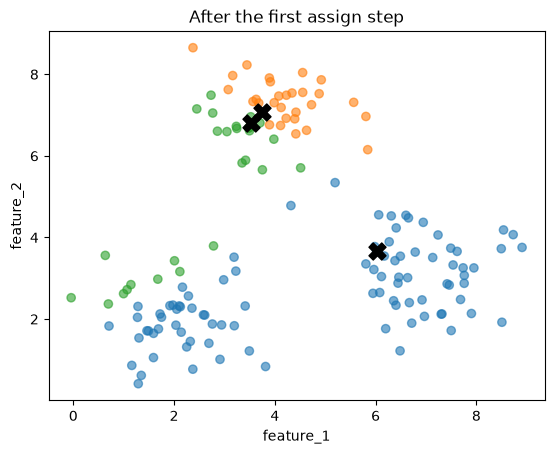

In [27]:
plot_clusters(X, labels, centroids, title='After the first assign step')

Every point now belongs to the cluster of its nearest centroid. The two centroids in the top group split that group between them (orange and green). The third centroid takes the bottom right group and most of the bottom left group (blue), and a few points on the left edge go to green.

Update step: each centroid moves to the mean of its points. The arrows show how far each centroid moves.

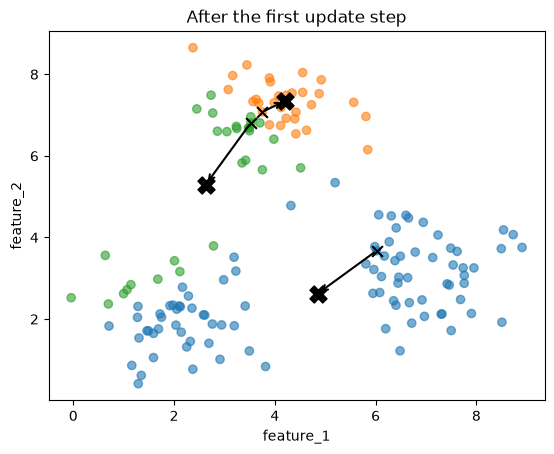

In [28]:
def update(X, labels, k):
    return np.array([X[labels == j].mean(axis=0) for j in range(k)])

new_centroids = update(X, labels, k)

plot_clusters(X, labels, new_centroids, title='After the first update step')
for old, new in zip(centroids, new_centroids):
    plt.annotate('', xy=new, xytext=old, arrowprops=dict(arrowstyle='->', lw=1.5))
plt.scatter(centroids[:, 0], centroids[:, 1], color='black', marker='x', s=60)  # old positions

Now we repeat the two steps until the centroids no longer move. We keep every set of centroids in a list called `history`, so that we can plot them afterwards.

In [29]:
centroids = X[start]
history = [centroids]

while True:
    labels = assign(X, centroids)
    new_centroids = update(X, labels, k)
    if np.allclose(new_centroids, centroids):  # the centroids did not move: stop
        break
    centroids = new_centroids
    history.append(centroids)

print(f"The centroids stopped moving after {len(history) - 1} updates.")

The centroids stopped moving after 4 updates.


One plot per step shows how the centroids travel. In each plot, the points are colored by their nearest centroid at that step, and the arrows show where each centroid came from.

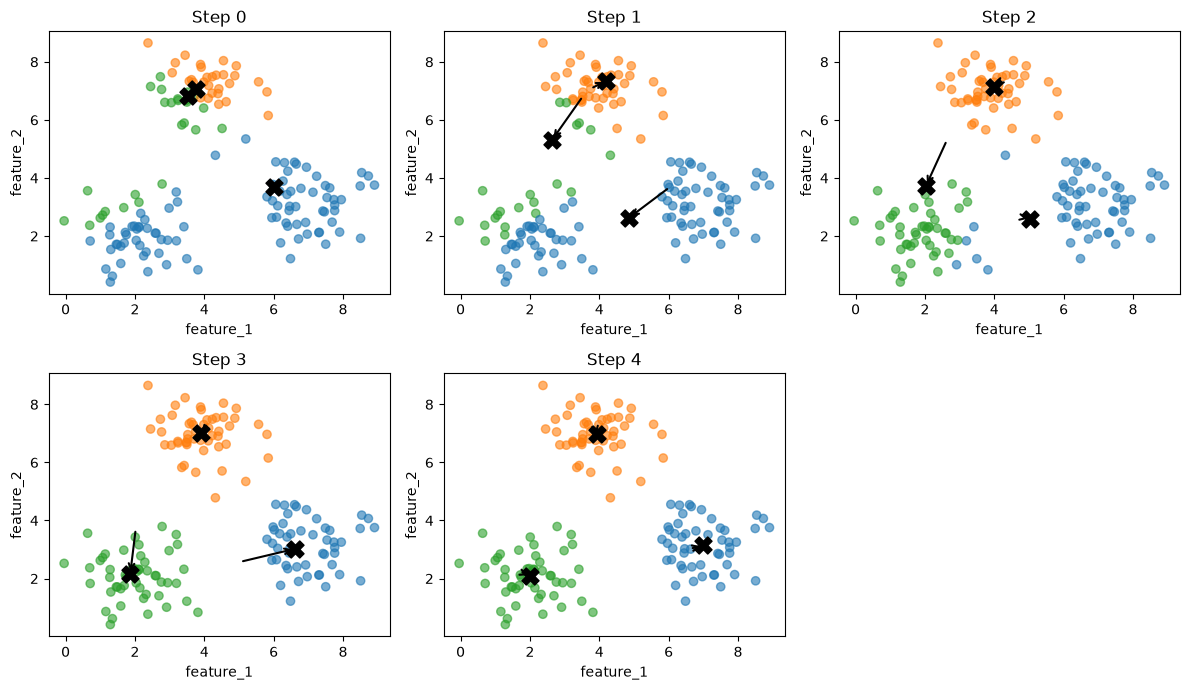

In [30]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7), dpi=100)
axes = axes.flatten()
for step, step_centroids in enumerate(history):
    ax = axes[step]
    plot_clusters(X, assign(X, step_centroids), step_centroids, ax=ax, title=f'Step {step}')
    if step > 0:
        for old, new in zip(history[step - 1], step_centroids):
            ax.annotate('', xy=new, xytext=old, arrowprops=dict(arrowstyle='->', lw=1.5))
for ax in axes[len(history):]:
    ax.axis('off')  # hide the unused plots
plt.tight_layout()

In step 1, the green centroid moves down, toward its points in the bottom left group, and the blue centroid moves toward the bottom left as well. In step 2, the green centroid reaches the bottom left group and takes it over. In steps 3 and 4, the blue centroid moves back to the bottom right group. In step 4, each centroid sits in the middle of one group, and another assign step would not change any point. The algorithm has converged.

We put the whole algorithm into one function, so that we can run it again with a different start.

In [31]:
def kmeans_by_hand(X, k, seed):
    np.random.seed(seed)
    centroids = X[np.random.choice(len(X), size=k, replace=False)]
    history = [centroids]
    while True:
        labels = assign(X, centroids)
        new_centroids = update(X, labels, k)
        if np.allclose(new_centroids, centroids):
            break
        centroids = new_centroids
        history.append(centroids)
    return labels, centroids, history

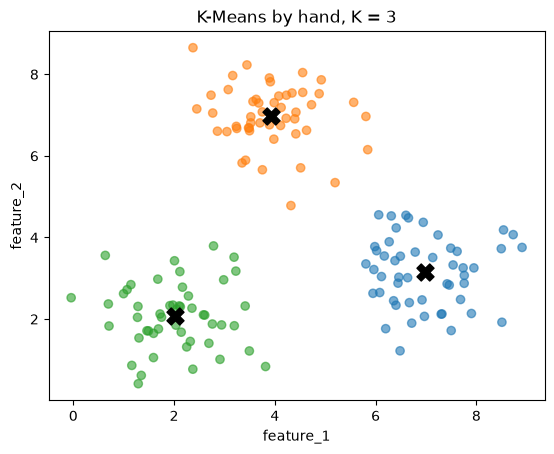

In [32]:
labels, centroids, history = kmeans_by_hand(X, k=3, seed=5)
plot_clusters(X, labels, centroids, title='K-Means by hand, K = 3')

### Comparing with scikit-learn

scikit-learn's `KMeans` from section 1 runs the same algorithm. To compare it with our version, we give it the same starting centroids with the `init` parameter. `n_init=1` tells it to run only once, from that start.

In [33]:
from sklearn.cluster import KMeans

start_centroids = history[0]
kmeans = KMeans(n_clusters=3, init=start_centroids, n_init=1)
kmeans.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",array([[6.019... 6.80966262]])
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",1
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",None
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[fl

In [34]:
print("scikit-learn:\n", kmeans.cluster_centers_)
print("by hand:\n", centroids)

scikit-learn:
 [[6.98502278 3.14619797]
 [3.92554141 6.97968697]
 [2.01344493 2.08224789]]
by hand:
 [[6.98502278 3.14619797]
 [3.92554141 6.97968697]
 [2.01344493 2.08224789]]


In [35]:
print("Same centroids:", np.allclose(kmeans.cluster_centers_, centroids))
print("Same labels:   ", np.array_equal(kmeans.labels_, labels))

Same centroids: True
Same labels:    True


The centroids and the labels match. Like the other scikit-learn models, a fitted `KMeans` can also make predictions for new points: `predict` gives a new point the label of its nearest centroid, which is our assign step.

In [36]:
new_point = np.array([[5.0, 5.0]])
print("scikit-learn:", kmeans.predict(new_point))
print("by hand:     ", assign(new_point, centroids))

scikit-learn: [1]
by hand:      [1]


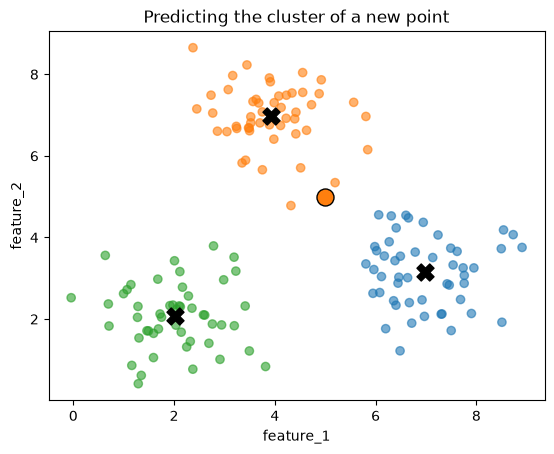

In [37]:
plot_clusters(X, kmeans.labels_, kmeans.cluster_centers_, title='Predicting the cluster of a new point')
plt.scatter(new_point[:, 0], new_point[:, 1], color=colors[kmeans.predict(new_point)], edgecolor='black', s=150)

### The starting centroids

The start matters. With seed 5, K-Means recovered from two centroids in the same group. Let's try seed 12.

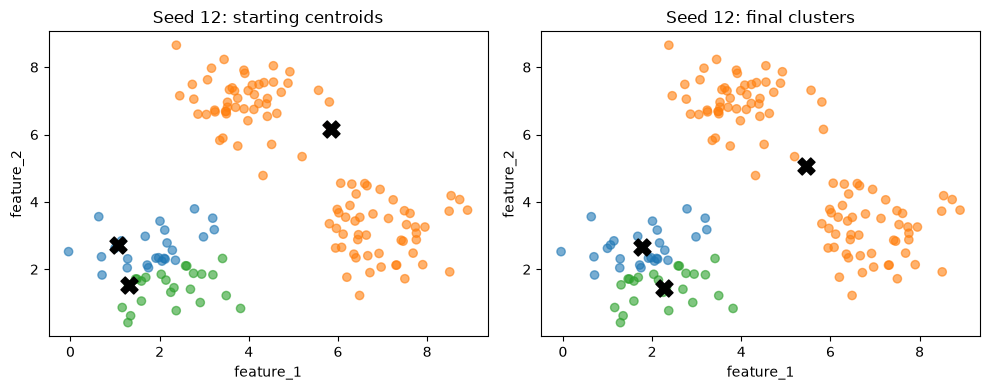

In [38]:
labels_bad, centroids_bad, history_bad = kmeans_by_hand(X, k=3, seed=12)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), dpi=100)
plot_clusters(X, labels_bad, history_bad[0], ax=axes[0], title='Seed 12: starting centroids')
plot_clusters(X, labels_bad, centroids_bad, ax=axes[1], title='Seed 12: final clusters')
plt.tight_layout()

This time K-Means stops with two centroids in the bottom left group and one centroid between the two other groups. Each step only moves the centroids a little, toward the middle of their current points. When no step improves the result, the algorithm stops, even if a much better set of clusters exists.

scikit-learn handles this in two ways:

* `init='k-means++'` (the default) does not pick the starting centroids completely at random. It picks them far apart from each other, which makes a bad start less likely.
* `n_init` runs K-Means several times from different starts and keeps the best result. Section 5 explains how it measures which result is best.

`random_state` fixes the random starts, so that you get the same result every time you run the cell.

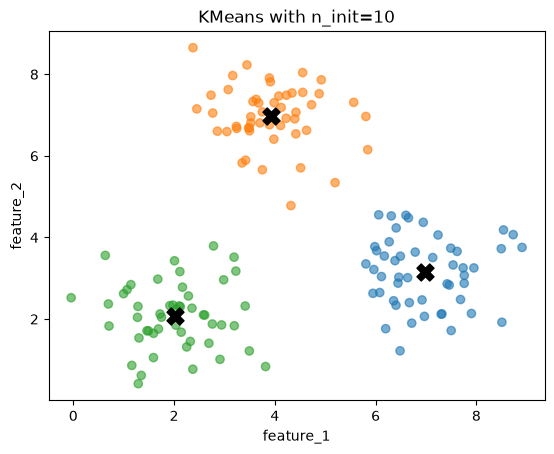

In [39]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=0)
kmeans.fit(X)
plot_clusters(X, kmeans.labels_, kmeans.cluster_centers_, title='KMeans with n_init=10')

## 5. Choosing k: inertia and the elbow

In section 4 we chose K = 3 because we made the data. With real data you do not know the number of clusters. To compare different results, we need a number that says how good a clustering is.

K-Means uses the **inertia**: the sum of the squared distances between each point and its centroid. Compact clusters, with points close to their centroids, have a low inertia.

In [40]:
inertia = 0
for x, label in zip(X, labels):
    inertia += distance(x, centroids[label]) ** 2

print(f"inertia by hand:      {inertia:.2f}")
print(f"inertia scikit-learn: {kmeans.inertia_:.2f}")

inertia by hand:      190.69
inertia scikit-learn: 190.69


The numbers match: `kmeans.inertia_` is the inertia of the fitted model. Let's draw the distances that go into it, as lines from each point to its centroid, for the good result (seed 5) and the bad result (seed 12).

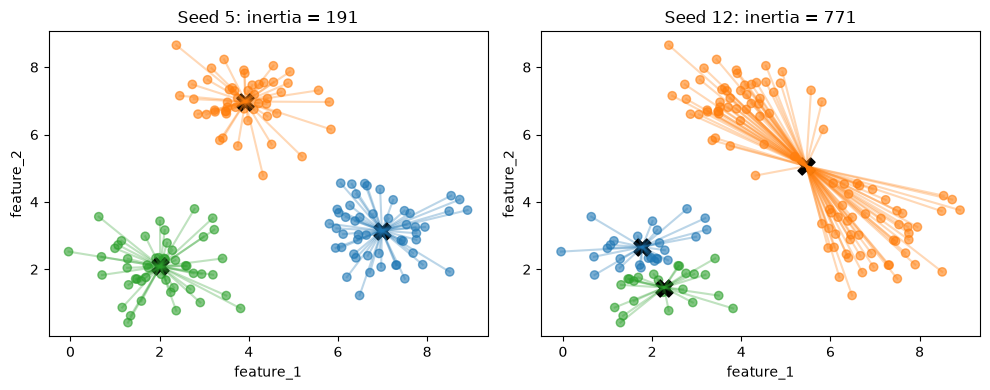

In [41]:
def inertia_of(X, labels, centroids):
    return sum(distance(x, centroids[label]) ** 2 for x, label in zip(X, labels))

fig, axes = plt.subplots(1, 2, figsize=(10, 4), dpi=100)
for ax, l, c, name in [(axes[0], labels, centroids, 'Seed 5'), (axes[1], labels_bad, centroids_bad, 'Seed 12')]:
    for x, label in zip(X, l):
        ax.plot([x[0], c[label][0]], [x[1], c[label][1]], color=colors[label], alpha=0.3)
    plot_clusters(X, l, c, ax=ax, title=f'{name}: inertia = {inertia_of(X, l, c):.0f}')
plt.tight_layout()

The bad result has much longer lines, so its inertia is about four times as large. This is how `n_init` picks the best of its runs: it keeps the run with the lowest inertia.

A first idea is to choose the K with the lowest inertia. Let's fit K-Means for K = 1 to 10 and plot the inertia.

Text(0, 0.5, 'inertia')

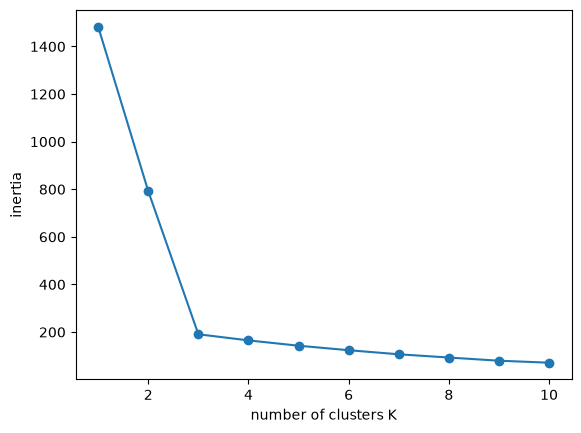

In [42]:
ks = range(1, 11)
inertias = []
for k in ks:
    model = KMeans(n_clusters=k, n_init=10, random_state=0)
    model.fit(X)
    inertias.append(model.inertia_)

plt.figure(dpi=100)
plt.plot(ks, inertias, marker='o')
plt.xlabel('number of clusters K')
plt.ylabel('inertia')

The inertia goes down with every extra cluster. More centroids means that every point is closer to some centroid. In the extreme case, with one cluster per point, every point is its own centroid and the inertia is zero.

In [43]:
model = KMeans(n_clusters=len(X), n_init=1, random_state=0)
model.fit(X)
print(f"inertia with {len(X)} clusters: {model.inertia_:.2f}")

inertia with 150 clusters: 0.00


So the lowest inertia always comes from the largest K. This is like the training cost on the [What is Machine Learning?](../theme-1/01_what_is_machine_learning.qmd) page (section 6), which kept going down as the degree of the polynomial went up.

Instead, look at the shape of the curve. From K = 1 to K = 3 the inertia drops quickly, because each new cluster separates a group that was not separated before. After K = 3 it drops slowly, because the new clusters only split groups that were already found. The point where the curve bends is called the elbow, and choosing K at the elbow is the **elbow method**. Here the elbow is at K = 3.

The plots below show what K = 2, 3 and 6 look like.

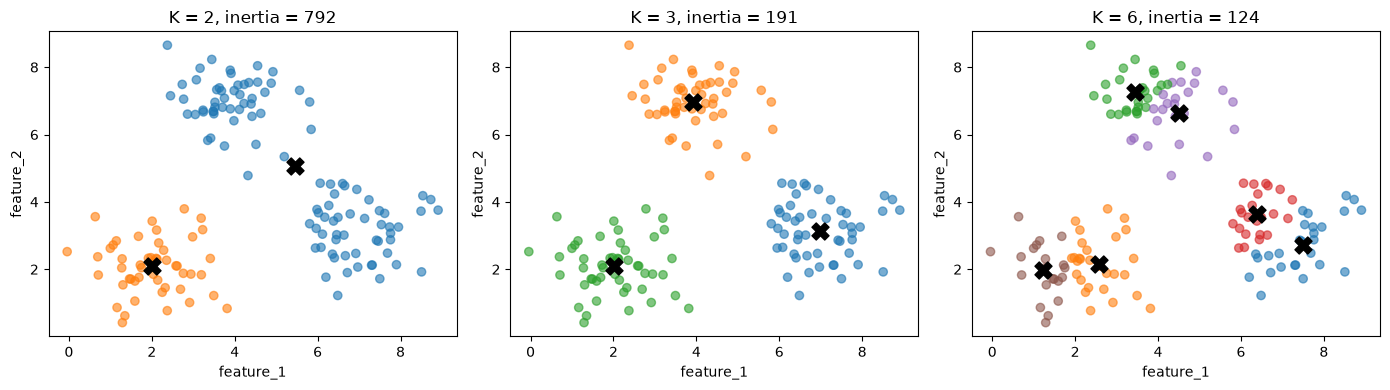

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), dpi=100)
for ax, k in zip(axes, [2, 3, 6]):
    model = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
    plot_clusters(X, model.labels_, model.cluster_centers_, ax=ax, title=f'K = {k}, inertia = {model.inertia_:.0f}')
plt.tight_layout()

With K = 2, two groups share a cluster. With K = 6, the inertia is lower than with K = 3, but the extra clusters cut real groups into pieces.

In real data the elbow is often not this clear: the curve can bend gradually, and then the elbow method does not point to one K. The silhouette score in the next section is a second measure you can use.

## 6. The silhouette score

A good cluster is compact, and it is well separated from the other clusters. The inertia only measures the first. The silhouette measures both, for every point:

* `a`: the mean distance from the point to the other points in its own cluster. Small is good.
* `b`: the mean distance from the point to the points of the nearest other cluster. Large is good.
* The silhouette of the point is

$$s = \frac{b - a}{\max(a, b)}$$

The value of `s` is between -1 and 1. Close to 1, the point is much closer to its own cluster than to any other cluster. Close to 0, the point is on the border between two clusters. Below 0, the point is closer to another cluster than to its own, which suggests it is in the wrong cluster.

We compute it by hand for the K = 3 result from section 4.

In [45]:
def silhouette_of_point(i, X, labels):
    own = labels[i]
    # a: mean distance to the other points of the own cluster
    others_in_own = [j for j in range(len(X)) if labels[j] == own and j != i]
    a = np.mean([distance(X[i], X[j]) for j in others_in_own])
    # b: mean distance to the points of the nearest other cluster
    b = min(np.mean([distance(X[i], X[j]) for j in range(len(X)) if labels[j] == other])
            for other in np.unique(labels) if other != own)
    return (b - a) / max(a, b)

In [46]:
silhouettes = np.array([silhouette_of_point(i, X, labels) for i in range(len(X))])
best, worst = np.argmax(silhouettes), np.argmin(silhouettes)
print(f"highest silhouette: point {best}, s = {silhouettes[best]:.2f}")
print(f"lowest silhouette:  point {worst}, s = {silhouettes[worst]:.2f}")

highest silhouette: point 134, s = 0.82
lowest silhouette:  point 118, s = 0.23


The plots show these two points. Solid lines go to the points of the own cluster (their mean is `a`), dashed lines go to the points of the nearest other cluster (their mean is `b`).

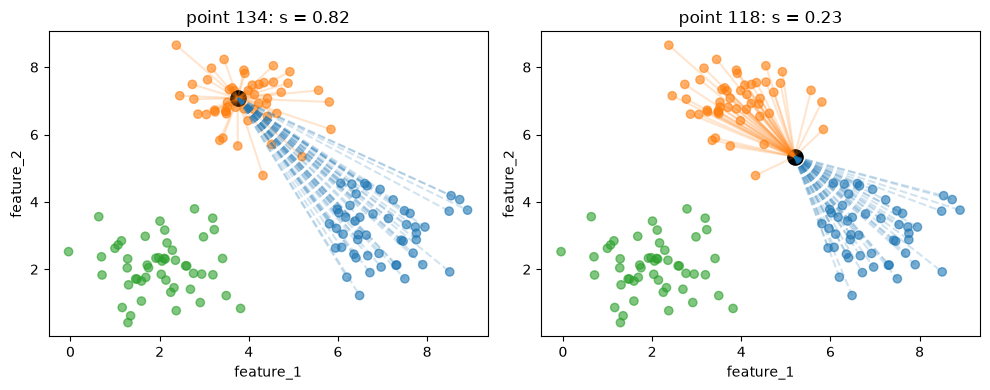

In [47]:
def nearest_other_cluster(i, X, labels):
    own = labels[i]
    others = [c for c in np.unique(labels) if c != own]
    mean_distances = [np.mean([distance(X[i], x) for x in X[labels == c]]) for c in others]
    return others[np.argmin(mean_distances)]

fig, axes = plt.subplots(1, 2, figsize=(10, 4), dpi=100)
for ax, i in zip(axes, [best, worst]):
    other = nearest_other_cluster(i, X, labels)
    for x in X[labels == labels[i]]:
        ax.plot([X[i, 0], x[0]], [X[i, 1], x[1]], color=colors[labels[i]], alpha=0.2)
    for x in X[labels == other]:
        ax.plot([X[i, 0], x[0]], [X[i, 1], x[1]], color=colors[other], alpha=0.2, ls='--')
    plot_clusters(X, labels, ax=ax, title=f'point {i}: s = {silhouettes[i]:.2f}')
    ax.scatter(X[i, 0], X[i, 1], color='black', s=120)
plt.tight_layout()

The point on the left lies deep inside its cluster: the solid lines are short and the dashed lines are long. The point on the right lies between two clusters. Its dashed lines are not much longer than its solid lines, so `s` is much lower. A point exactly on the border would have `s` = 0.

scikit-learn computes the silhouette of every point with `silhouette_samples`. Let's check our numbers.

In [48]:
from sklearn.metrics import silhouette_samples
np.allclose(silhouettes, silhouette_samples(X, labels))

True

Coloring every point by its silhouette shows where the clustering is uncertain.

Text(0, 0.5, 'feature_2')

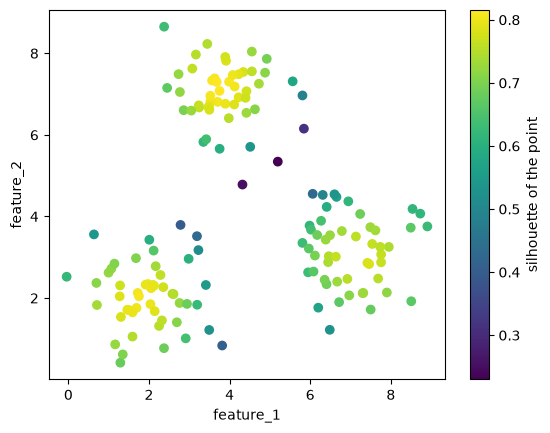

In [49]:
plt.figure(dpi=100)
plt.scatter(X[:, 0], X[:, 1], c=silhouettes, cmap='viridis')
plt.colorbar(label='silhouette of the point')
plt.xlabel('feature_1')
plt.ylabel('feature_2')

The points in the middle of each group have high values, and the points between groups have low values.

The **silhouette score** of a clustering is the mean silhouette of all points. scikit-learn computes it with `silhouette_score`.

In [50]:
from sklearn.metrics import silhouette_score
print(f"mean of our silhouettes:  {silhouettes.mean():.3f}")
print(f"silhouette_score:         {silhouette_score(X, labels):.3f}")
print(f"seed 12 (the bad result): {silhouette_score(X, labels_bad):.3f}")

mean of our silhouettes:  0.696
silhouette_score:         0.696
seed 12 (the bad result): 0.323


The bad result from section 4 has a lower silhouette score. Unlike the inertia, the silhouette score does not keep improving with more clusters, so you can look for the K with the highest score. It needs at least two clusters, because `b` needs another cluster, so we start at K = 2.

Text(0, 0.5, 'silhouette score')

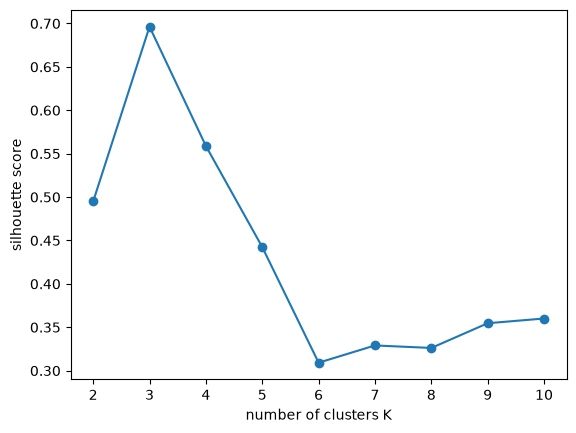

In [51]:
ks = range(2, 11)
scores = []
for k in ks:
    model = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
    scores.append(silhouette_score(X, model.labels_))

plt.figure(dpi=100)
plt.plot(ks, scores, marker='o')
plt.xlabel('number of clusters K')
plt.ylabel('silhouette score')

The silhouette score is highest at K = 3, the same answer as the elbow method.

The silhouette score only needs the data and the labels, so you can use it for any clustering algorithm, not only K-Means. For HDBSCAN, leave out the noise points (label `-1`) first, because noise is not a cluster. Section 8 does this.

The elbow and the silhouette score measure whether the clusters are compact and separated. They do not tell you whether the clusters are useful for your problem. Also look at the points in each cluster and check whether the groups make sense.

## 7. Where K-Means fails

K-Means gives every point to its nearest centroid. The border between two clusters is therefore a straight line, halfway between the two centroids. This works well for round groups of similar size, like the ones in section 4. It works badly for other shapes.

We make three datasets that break these assumptions:

* moons: two groups shaped like half circles;
* different densities: a small, tight group next to a large, spread-out group;
* outliers: two groups plus a few points far away from both.

In [52]:
# DUMMY DATA GENERATION
# DO NOT MODIFY
from sklearn.datasets import make_moons
X_moons, y_moons = make_moons(n_samples=300, noise=0.06, random_state=0)

np.random.seed(1)
tight = np.random.normal([0, 0], 0.3, size=(150, 2))
wide = np.random.normal([3, 0], 1.2, size=(150, 2))
X_density = np.concatenate([tight, wide])
y_density = np.array([0] * 150 + [1] * 150)

np.random.seed(2)
group_1 = np.random.normal([0, 0], 0.5, size=(100, 2))
group_2 = np.random.normal([4, 0], 0.5, size=(100, 2))
far_away = np.random.uniform([-6, -6], [10, 6], size=(15, 2))
X_outliers = np.concatenate([group_1, group_2, far_away])
y_outliers = np.array([0] * 100 + [1] * 100 + [-1] * 15)  # -1: outlier

datasets = {'moons': (X_moons, y_moons), 'different densities': (X_density, y_density),
            'outliers': (X_outliers, y_outliers)}

The top row shows the groups as we made them. The bottom row shows K-Means with K = 2 on the same data.

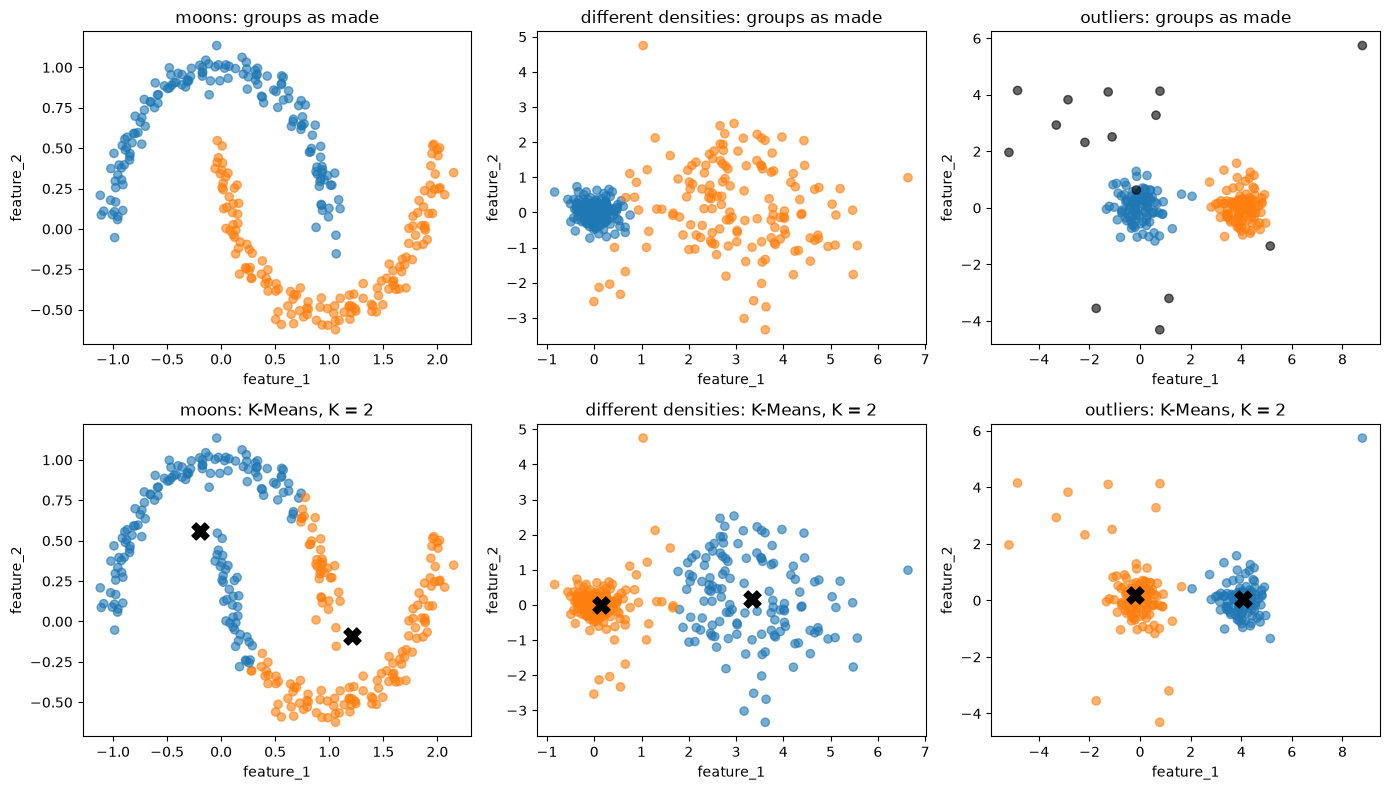

In [53]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8), dpi=100)
for col, (name, (X_d, y_d)) in enumerate(datasets.items()):
    # top: the groups we made (outliers in black)
    axes[0, col].scatter(X_d[:, 0], X_d[:, 1], color=np.where(y_d[:, None] == -1, [[0, 0, 0]], colors[y_d % 10]), alpha=0.6)
    axes[0, col].set_title(f'{name}: groups as made')
    axes[0, col].set_xlabel('feature_1')
    axes[0, col].set_ylabel('feature_2')
    # bottom: K-Means
    model = KMeans(n_clusters=2, n_init=10, random_state=0).fit(X_d)
    plot_clusters(X_d, model.labels_, model.cluster_centers_, ax=axes[1, col], title=f'{name}: K-Means, K = 2')
plt.tight_layout()

In all three cases the K-Means result differs from the groups we made:

* Moons: the straight border cuts each half circle in two.
* Different densities: the border lies halfway between the centroids, so the left part of the wide group goes to the tight group.
* Outliers: K-Means has no way to say that a point belongs to no cluster, so every far-away point is forced into one of the two clusters.

A different K does not fix this, because the problem is the shape of the clusters that K-Means can find.

## 8. Density-based clustering

**Density-based clustering** uses a different idea of a cluster: a region where many points are close together, separated from other clusters by regions with few points. The clusters can have any shape, and points in empty regions belong to no cluster.

The best-known algorithm is DBSCAN. It has two settings:

* `eps`: a radius. The neighbors of a point are all points within this distance, including the point itself.
* `min_samples`: the number of neighbors a point needs to lie in a dense region.

With these two settings, DBSCAN sorts the points into three kinds:

* A **core point** has at least `min_samples` neighbors.
* A **border point** is not a core point itself, but it lies within `eps` of a core point.
* A **noise point** is neither: it gets the label `-1`.

We sort the points of the moons dataset by hand. To make it more interesting, we add a few points far away from the moons.

In [54]:
# DUMMY DATA GENERATION
# DO NOT MODIFY
np.random.seed(3)
X_dense = np.concatenate([X_moons, np.random.uniform([-1.5, -1], [2.5, 1.5], size=(12, 2))])
eps = 0.15
min_samples = 5

In [55]:
D = pairwise_distances(X_dense)               # the distance matrix from section 2
n_neighbors = (D <= eps).sum(axis=1)          # how many points are within eps (including itself)
core = n_neighbors >= min_samples
border = ~core & (D[:, core] <= eps).any(axis=1)  # not core, but within eps of a core point
noise = ~core & ~border

print(f"core points:   {core.sum()}")
print(f"border points: {border.sum()}")
print(f"noise points:  {noise.sum()}")

core points:   295
border points: 5
noise points:  12


The plot draws the `eps` circle around one point of each kind. The core point has at least 5 points inside its circle. The border point has fewer, but one of them is a core point. The noise point has fewer and none of them is a core point.

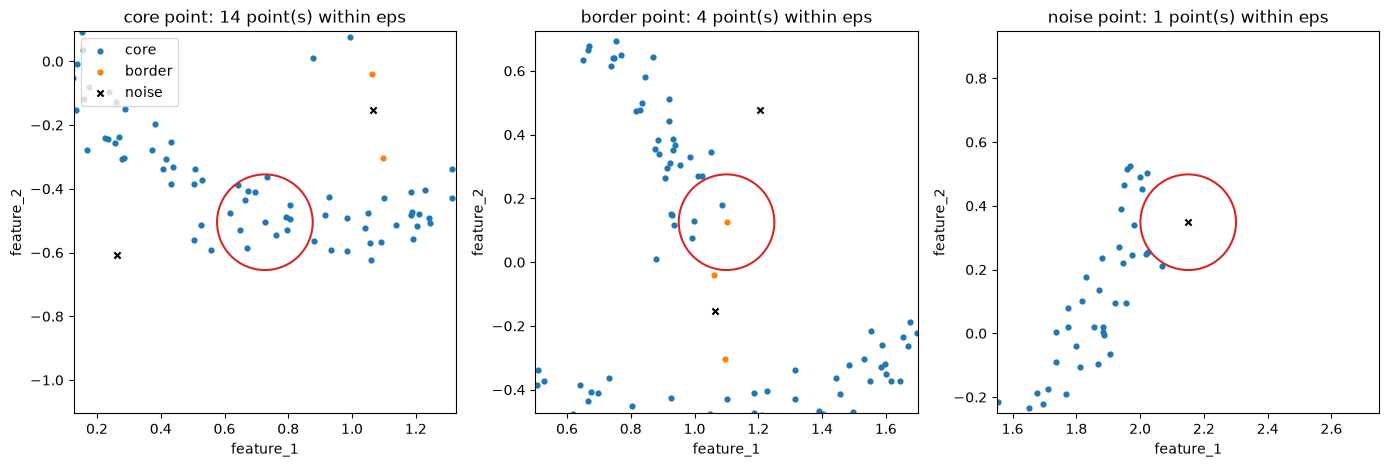

In [56]:
examples = {'core': np.where(core)[0][0], 'border': np.where(border)[0][0], 'noise': np.where(noise)[0][0]}

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), dpi=100)
for ax, (kind, i) in zip(axes, examples.items()):
    ax.scatter(X_dense[core, 0], X_dense[core, 1], color='tab:blue', s=12, label='core')
    ax.scatter(X_dense[border, 0], X_dense[border, 1], color='tab:orange', s=12, label='border')
    ax.scatter(X_dense[noise, 0], X_dense[noise, 1], color='black', marker='x', s=20, label='noise')
    ax.add_patch(plt.Circle(X_dense[i], eps, fill=False, color='tab:red', lw=1.5))
    ax.set_xlim(X_dense[i, 0] - 4 * eps, X_dense[i, 0] + 4 * eps)  # zoom in on the example point
    ax.set_ylim(X_dense[i, 1] - 4 * eps, X_dense[i, 1] + 4 * eps)
    ax.set_aspect('equal')
    ax.set_title(f'{kind} point: {n_neighbors[i]} point(s) within eps')
    ax.set_xlabel('feature_1')
    ax.set_ylabel('feature_2')
axes[0].legend(loc='upper left')
plt.tight_layout()

DBSCAN then builds the clusters from the core points. It starts at a core point and adds all its neighbors to the cluster. For every neighbor that is also a core point, it adds that point's neighbors too, and so on, until no new points can be added. That is one cluster. Then it starts again from a core point that is not yet in a cluster. Border points join the cluster of a nearby core point, and noise points stay alone.

scikit-learn's `DBSCAN` does all of this. Let's check that it finds the same core points and noise points as we did.

In [57]:
from sklearn.cluster import DBSCAN
dbscan = DBSCAN(eps=eps, min_samples=min_samples)
dbscan.fit(X_dense)

print("Same core points: ", np.array_equal(np.sort(dbscan.core_sample_indices_), np.where(core)[0]))
print("Same noise points:", np.array_equal(dbscan.labels_ == -1, noise))

Same core points:  True
Same noise points: True


To plot results with noise, we use a function that draws the noise points as black crosses, as in [Unsupervised Learning](../theme-1/05_unsupervised_learning.ipynb).

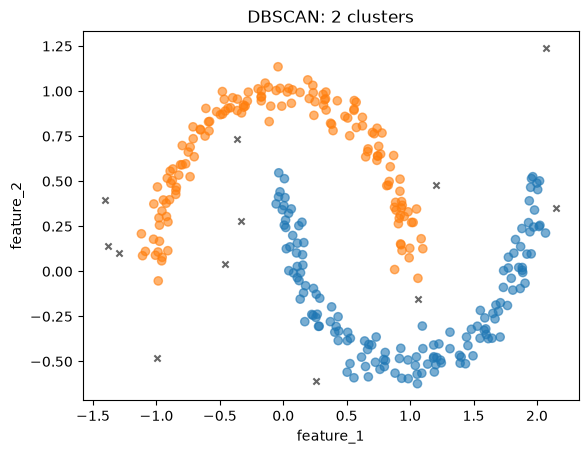

In [58]:
def plot_with_noise(X, labels, ax=None, title=None):
    if ax is None:
        plt.figure(dpi=100)
        ax = plt.gca()
    is_noise = labels == -1
    ax.scatter(X[is_noise, 0], X[is_noise, 1], color='black', marker='x', s=20, alpha=0.6)
    ax.scatter(X[~is_noise, 0], X[~is_noise, 1], color=colors[labels[~is_noise] % 10], alpha=0.6)
    ax.set_xlabel('feature_1')
    ax.set_ylabel('feature_2')
    if title is not None:
        ax.set_title(title)

plot_with_noise(X_dense, dbscan.labels_, title=f'DBSCAN: {len(set(dbscan.labels_) - {-1})} clusters')

DBSCAN finds the two half circles that K-Means cut in two, and it marks the far-away points as noise.

DBSCAN uses one radius `eps` for the whole dataset. That is a problem when clusters have different densities. The plots show DBSCAN on the different densities dataset from section 7 with a small and a large `eps`.

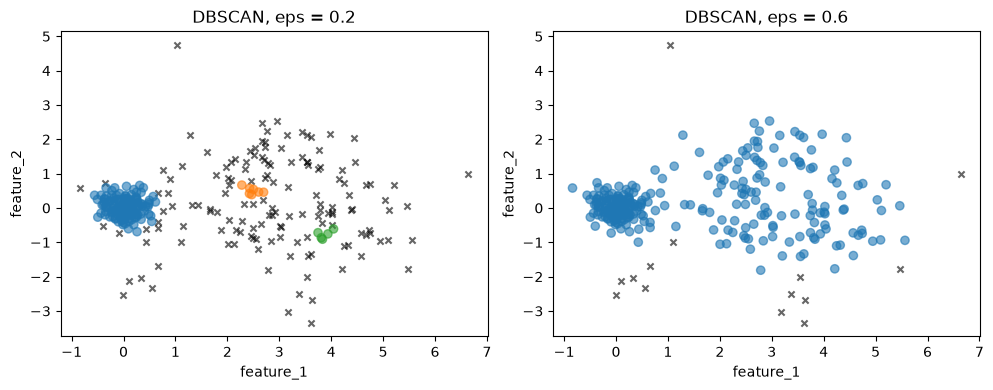

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), dpi=100)
for ax, e in zip(axes, [0.2, 0.6]):
    model = DBSCAN(eps=e, min_samples=5).fit(X_density)
    plot_with_noise(X_density, model.labels_, ax=ax, title=f'DBSCAN, eps = {e}')
plt.tight_layout()

With the small `eps`, the tight group is found, but most of the wide group becomes noise or small pieces. With the large `eps`, the wide group is found, but the gap between the groups is no longer empty enough, and the two groups join into one cluster. No single `eps` fits both groups.

HDBSCAN, the algorithm from [Unsupervised Learning](../theme-1/05_unsupervised_learning.ipynb), solves this. It looks at all values of `eps` at once and keeps the clusters that stay together over a wide range of them. Its main setting is `min_cluster_size`, the smallest group you want to call a cluster, which is easier to choose than `eps`.

Let's run HDBSCAN on the three datasets from section 7.

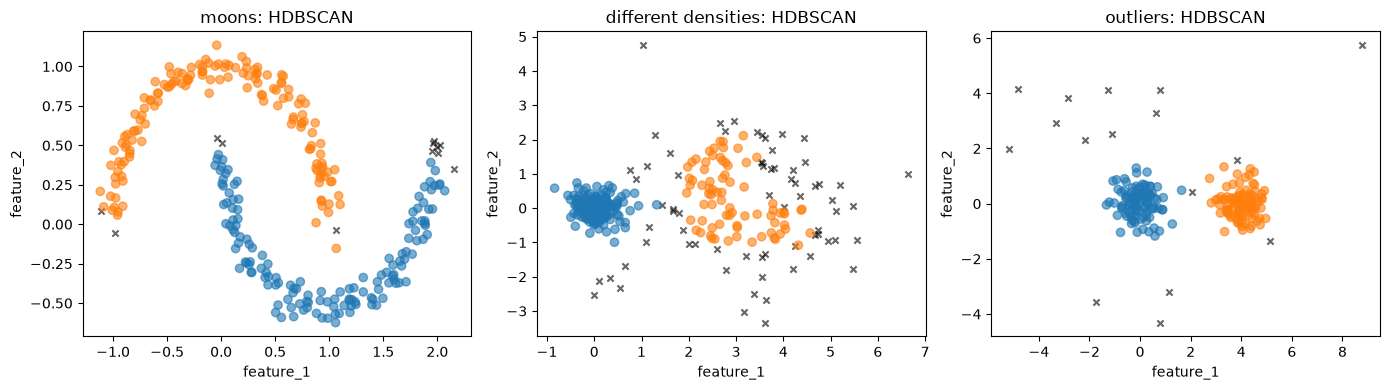

In [60]:
from sklearn.cluster import HDBSCAN

fig, axes = plt.subplots(1, 3, figsize=(14, 4), dpi=100)
for ax, (name, (X_d, y_d)) in zip(axes, datasets.items()):
    hdb = HDBSCAN(min_cluster_size=20, copy=True)  # copy=True: don't modify X in place
    hdb.fit(X_d)
    plot_with_noise(X_d, hdb.labels_, ax=ax, title=f'{name}: HDBSCAN')
plt.tight_layout()

HDBSCAN finds the two half circles, the tight and the wide group, and the two groups with the outliers as noise. Compare these plots with the K-Means row in section 7. HDBSCAN also marks points at the edges of the groups as noise. In the wide group, where the points are far apart, that is a large share of the points.

Finally, the silhouette score. As section 6 explained, we leave out the noise points first.

In [61]:
hdb = HDBSCAN(min_cluster_size=20, copy=True).fit(X_moons)
kept = hdb.labels_ != -1
kmeans_moons = KMeans(n_clusters=2, n_init=10, random_state=0).fit(X_moons)

print(f"silhouette score, HDBSCAN (without noise): {silhouette_score(X_moons[kept], hdb.labels_[kept]):.3f}")
print(f"silhouette score, K-Means:                 {silhouette_score(X_moons, kmeans_moons.labels_):.3f}")

silhouette score, HDBSCAN (without noise): 0.343
silhouette score, K-Means:                 0.488


K-Means gets the higher silhouette score, although HDBSCAN found the half circles and K-Means did not. The silhouette uses mean distances, so it rewards compact, round clusters. A half circle is long and curved: the points at its two ends are far apart, which makes `a` large. This is one more reason to look at the clusters themselves and not only at a score.

## 9. Exercise

<mark>YOUR TURN</mark>

Go back to the houses in California from [Unsupervised Learning](../theme-1/05_unsupervised_learning.ipynb). The code below loads the data and keeps the latitude and longitude, as in that notebook.

In [62]:
from sklearn.datasets import fetch_california_housing
X_cal, _ = fetch_california_housing(as_frame=True, return_X_y=True)
X_cal = X_cal[['Latitude', 'Longitude']]
X_cal.shape

(20640, 2)

1. Fit `KMeans` for K = 2 to 12 and plot the inertia (the elbow method) and the silhouette score against K. Which K would you choose?

   Tip: the silhouette compares every point with every other point, which is slow for 20,000 points. `silhouette_score(X, labels, sample_size=2000, random_state=0)` computes it on a random sample of 2,000 points.

In [63]:
# YOUR CODE HERE

2. Plot the K-Means clusters for the K you chose on the map (longitude on the x-axis, latitude on the y-axis). Then fit `HDBSCAN(min_cluster_size=500, copy=True)` as in [Unsupervised Learning](../theme-1/05_unsupervised_learning.ipynb) and plot its clusters next to them. Which method matches the cities better? Where does K-Means put the houses in the countryside between the cities?

In [64]:
# YOUR CODE HERE

3. Compute the silhouette score of the HDBSCAN clusters without the noise points, and compare it with the K-Means score. Does the higher score belong to the clustering you found more useful in question 2?

In [65]:
# YOUR CODE HERE

4. Take a moment to reflect: latitude and longitude are both measured in degrees. Should you scale them before clustering? What would scaling change about the distance between two houses?

Further reading: Géron, *Hands-On Machine Learning*, the chapter on unsupervised learning (the sections on K-Means and DBSCAN); James et al., [*An Introduction to Statistical Learning*](https://www.statlearning.com/) (free), the section on clustering methods.